# 20 · Fit weights, then test on new arrangement families

Fit a nonnegative simplex combination using training families only. Use a different family to choose the best single observable. Then compare both on three untouched arrangement families. Each held-out gallery contributes all six perturbation conditions and retains all four candidates.

The held-out top-1 results are 100% for the development-selected sign-aware pixel baseline, 96.0% for both trained profiles, and 79.3% for uniform fusion. The training-only rescaling does not change the selected component.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.stage5 import (COMPONENTS, CONDITIONS, SPLITS, make_images, similarity_profile,
                                weighted_similarity, run, paired_interval, explain)
OUT=ROOT/'results'/'stage5'
OUT.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()

## Training objective and controls
For the correct candidate $p$ and each incorrect candidate $n$, minimize the logistic ranking loss on the margin $w^T(d_n-d_p)$ with temperature 0.05 and a 0.02 penalty toward uniform weights. Both hyperparameters are fixed. Top-1 accuracy is measured separately. The development endpoint selects a single-component baseline, with alphabetical tie resolution.

A scale diagnostic repeats training after replacing $d_j$ by $d_j/(d_j+\tau_j)$. Here $\tau_j$ is the training median of the within-gallery distance range. A zero range is mapped to zero. Positive scales preserve each component's ranking. The calibration is pairwise and uses a frozen training constant, so it also works for standalone pairs.

In [3]:
pairs,decisions,info=run(OUT)
assert len(pairs)==4608 and len(decisions)==1152*9
assert pairs.groupby(['split','family','group','condition']).match.sum().eq(1).all()
for family,group in pairs.groupby('family'):
    assert group.split.nunique()==1
for fit in ['weights','scaled_weights']:
    w=np.array(list(info[fit].values()))
    assert (w>=0).all() and np.isclose(w.sum(),1)
display(pd.DataFrame({key:info[key] for key in ['weights','training_scales','scaled_weights']}).round(5))
print('Development-selected single:',info['selected_single'])

,weights,training_scales,scaled_weights
orientation histogram,0.0,0.00000,0.0
orientation pairs,0.0,0.23447,0.0
orientation triplets,0.0,0.30690,0.0
aligned orientation,1.0,0.35305,1.0
intensity power,0.0,0.00274,0.0
aligned sign-free pixels,0.0,0.08931,0.0


Development-selected single: aligned sign-free pixels


## Diagnose the difference between margins and rankings
An error with a small negative margin and a success with a small positive margin both receive substantial logistic loss. A method with consistently correct but small margins can lose to one with many larger margins and a few mistakes. Numerical distance scales and the decision objective both matter.

In [5]:
training=pairs[pairs.split=='train']
deltas=[]
for _,g in training.groupby(['family','group','condition']):
    d=g[list(COMPONENTS)].to_numpy()
    deltas.append(d[~g.match]-d[g.match])
delta=np.vstack(deltas)
display(pd.DataFrame({'positive margin fraction':(delta>1e-7).mean(0),
                      'mean margin':delta.mean(0),
                      'pair loss':np.logaddexp(0,-delta/.05).mean(0)},
                     index=COMPONENTS).round(4))

,positive margin fraction,mean margin,pair loss
orientation histogram,0.0000,0.0000,0.6931
orientation pairs,0.6979,0.1309,0.4670
orientation triplets,0.9115,0.2353,0.2627
aligned orientation,0.9922,0.2304,0.1354
intensity power,0.3021,-0.0017,0.7108
aligned sign-free pixels,1.0000,0.0837,0.3342


## Held-out outcomes and paired uncertainty
The experimental unit is the arrangement gallery. Each bootstrap draw resamples galleries within held-out families and keeps their views paired across methods. The three families are fixed and equally weighted. This quantifies variation across galleries within these generators.

method,aligned orientation,aligned sign-free pixels,intensity power,orientation histogram,orientation pairs,orientation triplets,scaled trained profile,trained profile,uniform profile
condition,,,,,,,,,
wave,1.000,1.0,0.031,0.25,1.000,1.000,1.000,1.000,1.000
ridge,1.000,1.0,0.042,0.25,0.344,0.990,1.000,1.000,1.000
bar,1.000,1.0,0.010,0.25,0.469,1.000,1.000,1.000,1.000
mixed noise 1,0.990,1.0,0.021,0.25,0.062,0.469,0.990,0.990,0.667
mixed noise 2,0.771,1.0,0.146,0.25,0.000,0.292,0.771,0.771,0.406
occlusion,1.000,1.0,0.062,0.25,0.104,0.583,1.000,1.000,0.688


,method,baseline,difference,low95,high95
0,uniform profile,aligned sign-free pixels,-0.2066,-0.2362,-0.1771
1,trained profile,aligned sign-free pixels,-0.0399,-0.0538,-0.0260
2,scaled trained profile,aligned sign-free pixels,-0.0399,-0.0538,-0.0260


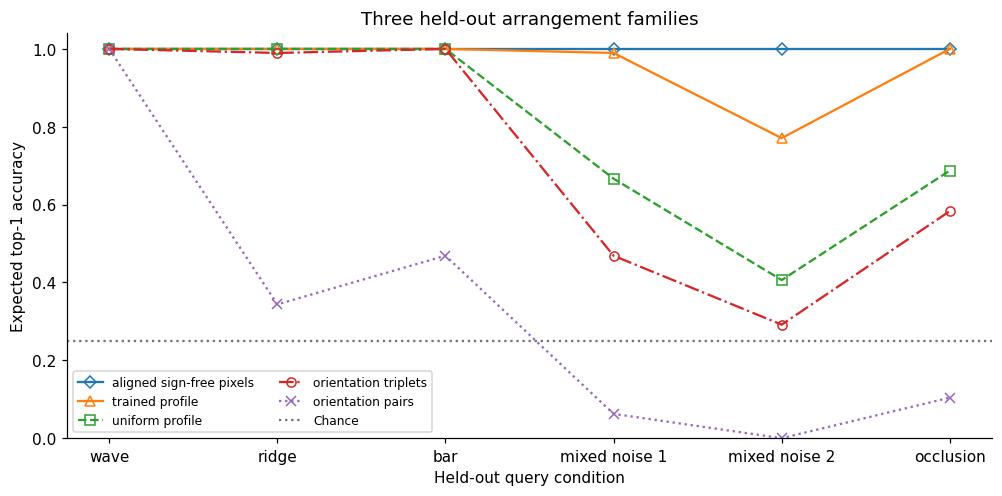

In [7]:
test=decisions[decisions.split=='test']
table=test.groupby(['condition','method']).top1.mean().unstack().loc[list(CONDITIONS)]
display(table.round(3))
results=[]
for name in ['uniform profile','trained profile','scaled trained profile']:
    results.append((name,info['selected_single'],*paired_interval(test,name,info['selected_single'])))
intervals=pd.DataFrame(results,columns=['method','baseline','difference','low95','high95'])
display(intervals.round(4));intervals.to_csv(OUT/'paired_differences.csv',index=False)
selected=['aligned sign-free pixels','trained profile','uniform profile','orientation triplets','orientation pairs']
fig,ax=plt.subplots(figsize=(9,4.4))
for method,style in zip(selected,['D-','^-','s--','o-.','x:']):
    ax.plot(range(len(table)),table[method],style,label=method,markerfacecolor='none')
ax.axhline(.25,color='.45',ls=':',label='Chance')
ax.set(xlabel='Held-out query condition',ylabel='Expected top-1 accuracy',ylim=(0,1.04),
       xticks=range(len(table)),xticklabels=table.index,title='Three held-out arrangement families')
ax.legend(fontsize=8,ncol=2)
show('20_heldout_retrieval')

## Interpretation
The selected single baseline is a control for claiming value from fusion. Its pixel comparison is strong because the permitted transformations and tile frame are known. Report the complete profile even when only one component supports the decision. A nonzero weight describes the fitted objective, not an independent measure of a component's usefulness.